In [2]:
import numpy as np
import pandas as pd

In [3]:
data= np.load("user_cluster_dict_and_cluster_top_users.npz", allow_pickle=True)

In [4]:
user_cluster_dict= data["user_cluster_dict"].item()
cluster_top_users= data["cluster_top_users"].item()

In [5]:
meta_df= pd.read_csv("meta_data_training.csv")

In [6]:
meta_df.drop(columns="Unnamed: 0", inplace= True)

In [7]:
meta_df["cluster"] = meta_df["username"].map(user_cluster_dict)

In [8]:
meta_df.head(10)

,username,tweet_count,hashtags_per_tweet,urls_per_tweet,mentions_per_tweet,retweet_ratio,reply_ratio,avg_tweet_len,caps_ratio,emoji_ratio,emoji_count_ratio,exclamation_ratio,link_tweet_ratio,no_link_tweet_ratio,tweets_per_day,mentioned_by_others,cluster
0,0000000000000b2,1,1.000000,0.0,1.000000,0.0,1.000000,33.000000,0.000000,0.000000,0.000000,0.000000,0.0,1.0,1.000,0.0,13
1,0000000000KAIJU,2,0.500000,0.0,0.500000,0.0,0.500000,62.000000,0.000000,0.000000,0.000000,0.000000,0.0,1.0,1.000,1.0,20
2,000000000OOK,9,0.222222,0.0,0.888889,0.0,0.666667,146.666667,0.333333,0.222222,0.222222,0.000000,0.0,1.0,1.125,4.0,10
3,00000000FF00,1,0.000000,0.0,1.000000,0.0,1.000000,75.000000,0.000000,0.000000,0.000000,0.000000,0.0,1.0,1.000,0.0,24
4,00000000jn,1,0.000000,0.0,1.000000,0.0,1.000000,22.000000,0.000000,0.000000,0.000000,0.000000,0.0,1.0,1.000,0.0,11
5,00000001Bot,2,0.000000,0.0,0.000000,0.0,0.000000,261.500000,1.000000,0.000000,0.000000,0.500000,0.0,1.0,1.000,0.0,19
6,00000001_,9,1.333333,0.0,0.666667,0.0,0.333333,139.777778,0.222222,0.000000,0.000000,0.000000,0.0,1.0,1.125,3.0,10
7,0000000a77,1,0.000000,0.0,0.000000,0.0,0.000000,15.000000,0.000000,0.000000,0.000000,0.000000,0.0,1.0,1.000,0.0,13
8,0000000dead,2,0.000000,0.0,2.000000,0.0,1.000000,262.500000,0.000000,0.000000,0.000000,0.500000,0.0,1.0,2.000,0.0,2
9,000000Uro,11,0.000000,0.0,0.181818,0.0,0.181818,45.181818,0.090909,0.272727,0.272727,0.090909,0.0,1.0,1.100,0.0,20


In [9]:
meta_df.drop(columns=["tweet_count","emoji_count_ratio","link_tweet_ratio","no_link_tweet_ratio"], inplace= True)

In [10]:
meta_df.columns

Index(['username', 'hashtags_per_tweet', 'urls_per_tweet',
       'mentions_per_tweet', 'retweet_ratio', 'reply_ratio', 'avg_tweet_len',
       'caps_ratio', 'emoji_ratio', 'exclamation_ratio', 'tweets_per_day',
       'mentioned_by_others', 'cluster'],
      dtype='object')

In [11]:
cols_to_agg = meta_df.columns.difference(["username", "cluster"])

grouped = (
    meta_df
    .groupby("cluster")[cols_to_agg]
    .agg([
        "mean",
        lambda x: x.quantile(0.25),
        lambda x: x.quantile(0.75),
    ])
)

# Optional: Namen für die Lambdas setzen
grouped = grouped.rename(
    columns={
        "<lambda_0>": "q25",
        "<lambda_1>": "q75"
    },
    level=1
)

In [12]:
grouped.head(30)

avg_tweet_len                         caps_ratio                      \
                 mean         q25         q75       mean       q25       q75   
cluster                                                                        
0           77.508538   41.950000   97.333333   0.125085  0.000000  0.000000   
1           90.128319   66.000000  111.000000   0.176941  0.000000  0.285714   
2          167.117709  127.000000  205.000000   0.164949  0.000000  0.000000   
3          200.061875  149.375000  258.331140   0.515966  0.000000  1.000000   
4          100.712812   53.000000  119.000000   0.177979  0.000000  0.000000   
5          109.153681   75.000000  141.000000   0.486406  0.000000  1.000000   
6          225.691115  195.333333  260.419643   0.787640  0.666667  1.000000   
7          195.488465  166.500000  222.000000   0.631212  0.000000  1.000000   
8          150.551291  110.000000  186.666667   0.128198  0.000000  0.000000   
9           96.247000   70.000000  118.000000   0.118829  0.000000  0.000000   
10         169.456806  134.750000  203.000000   0.165963  0.000000  0.222222   
11          26.673199   19.000000   31.000000   0.025037  0.000000  0.000000   
12         150.810952  114.792105  185.888889   0.551283  0.222222  1.000000   
13          38.223714   27.500000   46.000000   0.095343  0.000000  0.000000   
14         125.819938   70.000000  171.000000   0.905621  1.000000  1.000000   
15         121.304705   86.000000  145.000000   0.147670  0.000000  0.166667   
16          53.616131   31.000000   66.000000   0.129666  0.000000  0.000000   
17         118.549557   73.000000  151.000000   0.184919  0.000000  0.230769   
18         164.808421  124.885621  199.500000   0.246970  0.000000  0.428571   
19         240.378036  206.088942  278.000000   0.404960  0.000000  1.000000   
20          62.375658   43.000000   74.000000   0.083095  0.000000  0.000000   
21          60.375878   42.000000   75.000000   0.195144  0.000000  0.250000   
22         265.173419  247.000000  287.500000   0.234795  0.000000  0.400000   
23         112.756959   89.500000  128.000000   0.268972  0.000000  0.500000   
24         110.043080   72.500000  137.000000   0.097909  0.000000  0.000000   

        emoji_ratio                 exclamation_ratio  ... reply_ratio  \
               mean   q25       q75              mean  ...         q75   
cluster                                                ...               
0          0.994987  1.00  1.000000          0.079002  ...    1.000000   
1          0.103895  0.00  0.142857          0.102569  ...    1.000000   
2          0.044873  0.00  0.000000          0.140903  ...    1.000000   
3          0.320880  0.00  0.733333          0.202712  ...    0.050000   
4          0.090943  0.00  0.000000          0.096480  ...    1.000000   
5          0.115564  0.00  0.000000          0.114642  ...    1.000000   
6          0.113572  0.00  0.062500          0.140376  ...    1.000000   
7          0.192511  0.00  0.227273          0.379253  ...    0.000000   
8          0.116398  0.00  0.000000          0.086375  ...    1.000000   
9          0.084892  0.00  0.000000          0.110148  ...    1.000000   
10         0.034595  0.00  0.000000          0.064938  ...    1.000000   
11         0.005691  0.00  0.000000          0.036340  ...    1.000000   
12         0.199274  0.00  0.333333          0.206356  ...    0.285714   
13         0.052094  0.00  0.000000          0.085337  ...    1.000000   
14         0.135157  0.00  0.000000          0.256495  ...    0.600000   
15         0.055427  0.00  0.000000          0.075744  ...    1.000000   
16         0.881709  0.80  1.000000          0.073123  ...    1.000000   
17         0.877032  0.75  1.000000          0.137681  ...    1.000000   
18         0.051457  0.00  0.000000          0.084628  ...    0.500000   
19         0.190023  0.00  0.250000          0.202406  ...    0.789474   
20         0.052378  0.00  0.000000          0.067594  ...    1.0

In [13]:
grouped_flat= grouped.to_string()
grouped_reduced = grouped.loc[:, grouped.nunique() > 1]
grouped_reduced_flat= grouped_reduced.to_string()

In [14]:
print(grouped_reduced_flat)

        avg_tweet_len                         caps_ratio                     emoji_ratio                 exclamation_ratio           hashtags_per_tweet                 mentioned_by_others      mentions_per_tweet                     reply_ratio                     retweet_ratio tweets_per_day           urls_per_tweet
                 mean         q25         q75       mean       q25       q75        mean   q25       q75              mean       q75               mean  q25        q75                mean  q75               mean       q25       q75        mean       q25       q75          mean           mean       q75           mean
cluster                                                                                                                                                                                                                                                                                                                      
0           77.508538   41.950000   97.333333 

In [15]:
chunks= []
for chunk in pd.read_csv("bitcoin_tweets.csv", chunksize=1000000):
    chunks.append(chunk)

df_tweets= pd.concat(chunks)

In [16]:
df_tweets.columns

Index(['Unnamed: 0', 'datetime', 'username', 'text'], dtype='object')

In [17]:
df_tweets.drop(columns= "Unnamed: 0", inplace= True)

In [18]:
cutoff_date = pd.Timestamp('2021-10-19', tz= 'UTC')

In [19]:
df_tweets["datetime"] = pd.to_datetime(df_tweets["datetime"])
mask = (df_tweets['datetime'] <= cutoff_date)
df_tweets = df_tweets.loc[mask]

In [20]:
df_text= df_tweets.drop(columns= "datetime")

In [21]:
username_to_cluster = {user: cluster for cluster, users in cluster_top_users.items() for user in users}

In [22]:
df_text['cluster_label'] = df_text['username'].map(username_to_cluster)

In [23]:
df_text = df_text.dropna(subset=['cluster_label'])

In [24]:
df_text = df_text.sort_values(by=['cluster_label', 'username']).reset_index(drop=True)

In [25]:
df=df_text[df_text['cluster_label'] == 24].drop(columns="cluster_label")
df_dict= df.groupby("username")["text"].apply(list).to_dict()

In [26]:
df_dict

{'Mr___Gitau': ["@KoneMoheavy Definitely\nAlafu they can't trace him because he uses bitcoin",
  '@KoneMoheavy Maze nigga went MIA to live the good life\nHe had approximately a billion bitcoin when aliingia mitini',
  '@ClemoFrank Bitcoin is a future investment\nThe best thing is to buy and hold, it will benefit 5 yrs, 10 yrs to come\nThe future is technology based',
  '@Hey__Z Yes, lakini si that substantial. Nikipata good cash, am definitely converting it into bitcoin. Kwanza sahii its the best time to buy, from this low, the only way is up',
  "@ShankiAustine Don't see it replacing ksh\nRather they will work hand in hand\nYou can pay through bitcoin and ksh",
  '@Hey__Z Bitcoin is the future bro\nNow is the best time to invest'],
 'MrsSheaSmith': ["@TheMoonCarl I didn't sell bitcoin too, hodl in Ownr",
  '@HanaHausnerova bitcoin motivates me. I think its a great opportunity to make our life brighter and better.',
  "@TheMoonCarl @amazon don't want to sell bitcoin now...",
  'First r

In [27]:
cluster_labels_dict= {
    0: "Emoji-Memer / Casual Bitcoin-Chat",
    1: "Bitcoin-Maximalisten & Crypto-Debattierer (Reply-getrieben)",
    2: "Diskussionsorientierte Skeptiker & Tech-Debattierer",
    3: "Promo-/Shill-Accounts (NFT-, Merch- & Altcoin-Marketing mit Bitcoin-Hashtags)",
    4: "Altcoin-/Memecoin-Hype & Shill-Community (BTC als Referenz/Hashtag)",
    5: "Airdrop-/Giveaway-Jäger (Promo-/Engagement-Spam mit BTC-Hashtag)",
    6: "Airdrop-/Bounty-Spammer (Task-Fulfillment & Wallet-Drops mit BTC-Hashtag)",
    7: "LATOKEN-Giveaway/Airdrop-Promoter (Referral-/Task-Spam mit BTC-Branding)",
    8: "Retail-Crypto-Kommentatoren (Meinungs-/Debatten- und Trader-Talk rund um Bitcoin)",
    9: "Bitcoin-/Crypto-Twitter-Kommentatoren & Trader-Talk (Meinung, Sentiment, Memes)",
    10: "Bitcoin-Maximalisten / Ideologisch-überzeugte Hodler",
    11: "Low-Effort Bitcoin-Reply-Spam / Engagement-Farmer",
    12: "Retail-Crypto-Trader & Hype/Promo-Accounts",
    13: "Bitcoin-Maximalisten / Meme-HODL-Community",
    14: "Hype-/Promo-Spammer (Airdrops, Pump-Calls, Link-Shills)",
    15: "Ideologische Bitcoin-Debattierer & Maxi-Advocates",
    16: "Bitcoin-Fans & Meme-/Hype-Poster (Community-Cheerleader)",
    17: "Retail-Crypto-Chatter (Meme/Emotion + Price-Talk)",
    18: "Bitcoin News-Curators & Edu-Advocates (Informations-/Adoptions-Promoter)",
    19: "Retail-Trader & Crypto-Debate Community (Trading-Fokus mit gemischten Meinungen)",
    20: "Bitcoin-Maxis & Hype-Retail (HODL-/Moon-Community)",
    21: "Crypto-Trader & Meme-Speculator (Pump/Dip-Community)",
    22: "Bitcoin-Debattierer & Skeptische Analysten (Policy/Tech/Critique)",
    23: "Bitcoin News-Amplifier & Bullish Adoption-Promoter",
    24: "Retail-Hodler & Bitcoin-Believer (Community-Level Investoren)"
}

In [28]:
"""
0: Casual Meme & Emoji (Low-Info BTC Chat)
1: Maxi-Debatte – Reply-getrieben (BTC vs ETH/Alts)
2: Skepsis/Analyse – Tech/Policy-Debatte (kritisch, diskussionslastig)
3: Promo/Shill – Merch/NFT/Brand-Posts (BTC-Hashtag als Reichweite)
4: Alt-/Memecoin-Hype – BTC als Benchmark
5: Giveaway-Hunter – Engagement-Bait (RT/Follow/Win)
6: Bounty/Task-Spam – Wallet/Proof-Posts
7: LATOKEN-spezifischer Airdrop/Referral-Spam
8: Trader-Kommentare – Marktmeinung/Setups (mehr „Trading“ als Meme)
9: Sentiment-Kommentare – Reactions/Hot Takes (mehr Stimmung als Trading)
10: Bitcoin-Maximalisten – Ideologie/Prinzipien (Sound money etc.)
11: Reply-Farming – Low-Effort BTC Responses
12: Hype/Promo – Pump-nahe Accounts (Calls, Overpromising, Links)
13: HODL-Meme-Community – Laser Eyes/Moon (Cheerleading)
14: Link-/Scam-nahe Promo-Spammer (Airdrop/Pump/“too good to be true”)
15: Maxi-Advocacy – argumentative Missionierer (überzeugen/belehren)
16: Fan-Cheerleader – positiv/Community (weniger ideologisch als 13/10)
17: Retail-Chatter – Preis/Emotion/Daily Talk (ohne klare Trading-Setups)
18: News-Kurator/Edu – Adoption & How-to
19: Debatten-Community – Trading vs Macro vs Narrative (Diskussion > Calls)
20: Maxi + Moon – Retail-Hype (starker BTC-Fokus + Euphorie)
21: Dip-Buyer/Pump-Meme – spekulativer Trader-Stil (BTFD, Valhalla etc.)
22: Kritische Debattierer – Policy/Tech/Risiken (Skepsis, Gegenargumente)
23: News-Amplifier – bullish Institutions/Adoption (Headline-Spam aber „News“)
24: Retail-Hodler – Buy&Hold/Lifestyle (Alltags-Hodl, „never sell“, Zukunft)
"""

'\n0: Casual Meme & Emoji (Low-Info BTC Chat)\n1: Maxi-Debatte – Reply-getrieben (BTC vs ETH/Alts)\n2: Skepsis/Analyse – Tech/Policy-Debatte (kritisch, diskussionslastig)\n3: Promo/Shill – Merch/NFT/Brand-Posts (BTC-Hashtag als Reichweite)\n4: Alt-/Memecoin-Hype – BTC als Benchmark\n5: Giveaway-Hunter – Engagement-Bait (RT/Follow/Win)\n6: Bounty/Task-Spam – Wallet/Proof-Posts\n7: LATOKEN-spezifischer Airdrop/Referral-Spam\n8: Trader-Kommentare – Marktmeinung/Setups (mehr „Trading“ als Meme)\n9: Sentiment-Kommentare – Reactions/Hot Takes (mehr Stimmung als Trading)\n10: Bitcoin-Maximalisten – Ideologie/Prinzipien (Sound money etc.)\n11: Reply-Farming – Low-Effort BTC Responses\n12: Hype/Promo – Pump-nahe Accounts (Calls, Overpromising, Links)\n13: HODL-Meme-Community – Laser Eyes/Moon (Cheerleading)\n14: Link-/Scam-nahe Promo-Spammer (Airdrop/Pump/“too good to be true”)\n15: Maxi-Advocacy – argumentative Missionierer (überzeugen/belehren)\n16: Fan-Cheerleader – positiv/Community (wenige

In [44]:
df_user= df_tweets.drop(columns= ["text"])

In [45]:
df_user["cluster"] = df_user["username"].map(user_cluster_dict)

In [46]:
df_user.drop(columns= "username", inplace= True)

In [47]:
df_user["datetime"] = pd.to_datetime(df_user["datetime"])
df_user = df_user.set_index("datetime")

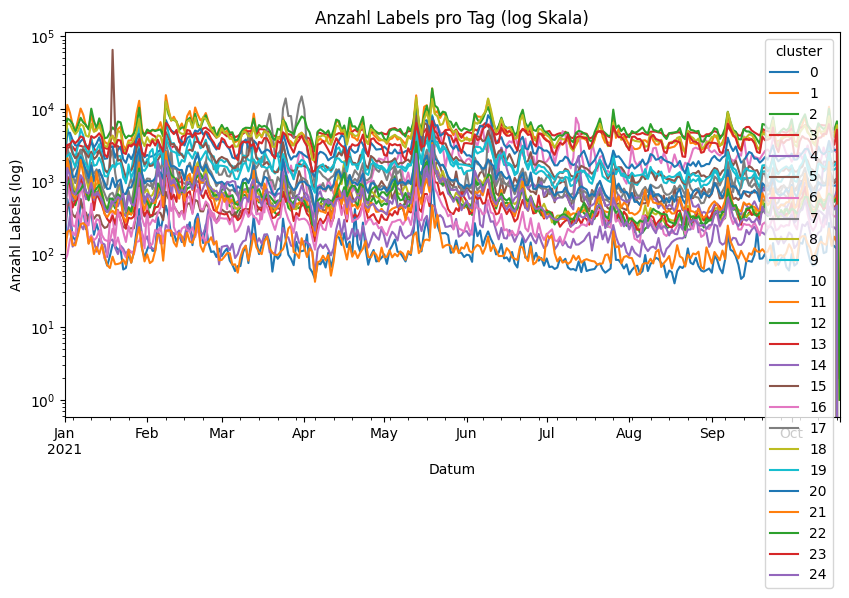

In [57]:
import matplotlib.pyplot as plt

# Gruppieren nach Tag und Label
counts = (
    df_user.groupby([pd.Grouper(freq="D"), "cluster"])
      .size()
      .unstack(fill_value=0)
)

# Plot
counts.plot(figsize=(10,5))
plt.yscale("log")   # 👈 logarithmische Skala
plt.ylabel("Anzahl Labels (log)")
plt.xlabel("Datum")
plt.title("Anzahl Labels pro Tag (log Skala)")
plt.show()